# 02 — Exploratory Data Analysis (UPI Pulse)

**Goal of this notebook:** understand the shape of India's UPI growth *before* we
build any model. Three views, then a written list of breaks and odd months.

**Data:** `data/processed/upi_monthly.csv` (built in Phase 1) — 126 months,
Apr 2016 → Sep 2026. Volume is in **millions of transactions**, value in **₹ crore**.

**Why we plot *average daily* volume, not the monthly total:** months have 28–31
days, so a 30-day month mechanically carries fewer transactions than a 31-day one.
Dividing by `days_in_month` removes that calendar artefact.

## Key dates we will refer to

| Window | Start | Why it matters |
|---|---|---|
| **Demonetisation** | Nov 2016 | ₹500/₹1000 notes withdrawn (8 Nov 2016) — pushed people to digital payments |
| **COVID lockdown** | Apr 2020 | national lockdown from 25 Mar 2020 — economic activity collapsed |
| **Main modelling window** | Apr 2021 | start of the period we will actually model (per project brief) |
| **Sensitivity window** | Jan 2019 | wider window, used to check the main-window results are robust |

We use **actual dates**, never "festival = November": Diwali moves between Oct and
Nov, so festival effects will later be built from real dates.

In [1]:
# --- libraries ---------------------------------------------------------------
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- notebook plotting defaults ---------------------------------------------
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- locate the project root regardless of where the kernel starts -----------
def find_project_root(start: Path) -> Path:
    # Walk up from `start` until we find data/processed/upi_monthly.csv.
    start = start.resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed" / "upi_monthly.csv").exists():
            return cand
    raise FileNotFoundError("Could not find data/processed/upi_monthly.csv")

PROJECT_ROOT = find_project_root(Path.cwd())
DATA   = PROJECT_ROOT / "data" / "processed" / "upi_monthly.csv"
FIGDIR = PROJECT_ROOT / "notebooks" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

# --- key dates ---------------------------------------------------------------
MODEL_START = pd.Timestamp("2021-04-01")   # main modelling window
SENS_START  = pd.Timestamp("2019-01-01")   # sensitivity window
DEMON       = pd.Timestamp("2016-11-01")   # demonetisation
COVID       = pd.Timestamp("2020-04-01")   # COVID lockdown

print("Model start:", MODEL_START.date(), "| Sensitivity start:", SENS_START.date())

Project root: C:\UPI PowerBI
Model start: 2021-04-01 | Sensitivity start: 2019-01-01


In [2]:
# --- load the cleaned monthly table -----------------------------------------
df = pd.read_csv(DATA, parse_dates=["month"])
df = df.sort_values("month").reset_index(drop=True)

print("shape          :", df.shape)
print("month range    :", df["month"].min().date(), "->", df["month"].max().date())
print("distinct months:", df["month"].nunique())
print("missing months :", len(pd.date_range(df["month"].min(), df["month"].max(), freq="MS")) - df["month"].nunique())
df.head()

shape          : (126, 14)
month range    : 2016-04-01 -> 2026-09-01
distinct months: 126
missing months : 0


,month,year,month_num,volume_mn,value_cr,banks_live,days_in_month,avg_daily_volume,avg_daily_value,avg_ticket_size_inr,yoy_volume_pct,mom_volume_pct,yoy_value_pct,mom_value_pct
0,2016-04-01,2016,4,0.00,0.00,21.0,30,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
1,2016-05-01,2016,5,0.00,0.00,21.0,31,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
2,2016-06-01,2016,6,0.00,0.00,21.0,30,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
3,2016-07-01,2016,7,0.09,0.38,21.0,31,0.002903,0.012258,42.222222,NaN,NaN,NaN,NaN
4,2016-08-01,2016,8,0.09,3.09,21.0,31,0.002903,0.099677,343.333333,NaN,0.0,NaN,713.157895


## Plot 1 — Average daily volume (log scale)

A **log scale** lets us see both the near-zero launch year (2016) *and* the huge
later values on one chart: each step up the axis is a ×10 change, not a +constant.

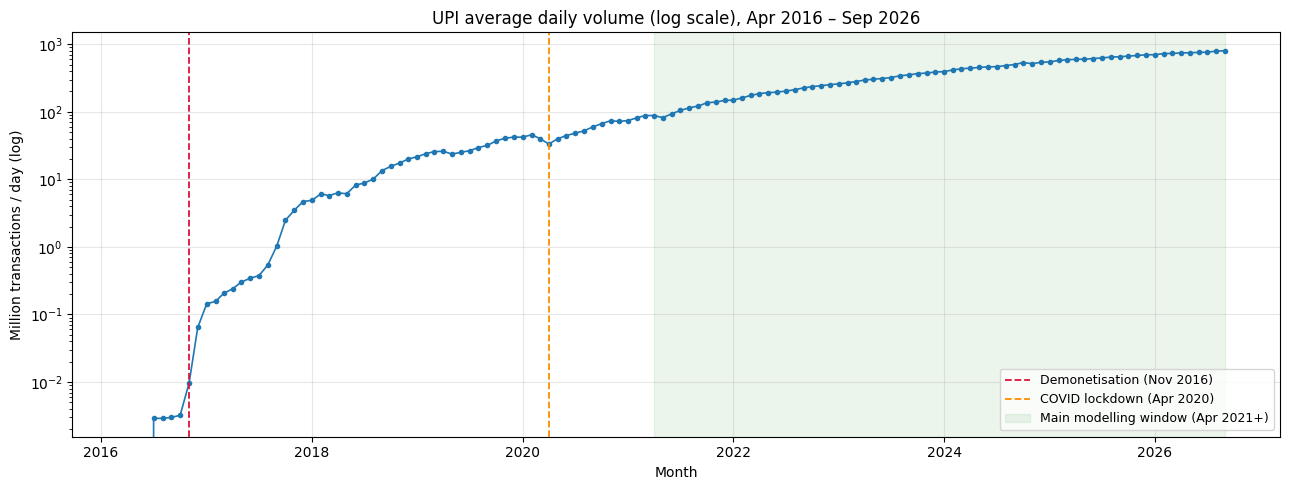

2016-04 : 0.0 Mn/day
2026-09 : 802.279 Mn/day


In [3]:
fig, ax = plt.subplots()
ax.plot(df["month"], df["avg_daily_volume"], marker="o", ms=3, lw=1.2, color="#1f77b4")

# structural-break markers
ax.axvline(DEMON, color="crimson", ls="--", lw=1.3, label="Demonetisation (Nov 2016)")
ax.axvline(COVID, color="darkorange", ls="--", lw=1.3, label="COVID lockdown (Apr 2020)")
# main modelling window (Apr 2021 onward)
ax.axvspan(MODEL_START, df["month"].max(), color="green", alpha=0.08,
           label="Main modelling window (Apr 2021+)")

ax.set_yscale("log")
ax.set_title("UPI average daily volume (log scale), Apr 2016 – Sep 2026")
ax.set_ylabel("Million transactions / day (log)")
ax.set_xlabel("Month")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGDIR / "01_avg_daily_volume_log.png", dpi=120)
plt.show()

print("2016-04 :", round(df.loc[df.month == '2016-04-01', 'avg_daily_volume'].iloc[0], 4), "Mn/day")
print("2026-09 :", round(df.loc[df.month == '2026-09-01', 'avg_daily_volume'].iloc[0], 3), "Mn/day")

## Plot 2 — Average ticket size (₹ per transaction)

Ticket size = value ÷ volume, converted to rupees. It tells us whether UPI is
growing from **more people** or from **bigger payments**. Values before 2017 are
noisy because the volumes were tiny (a single large transfer could move the
average), so read the post-2017 line.

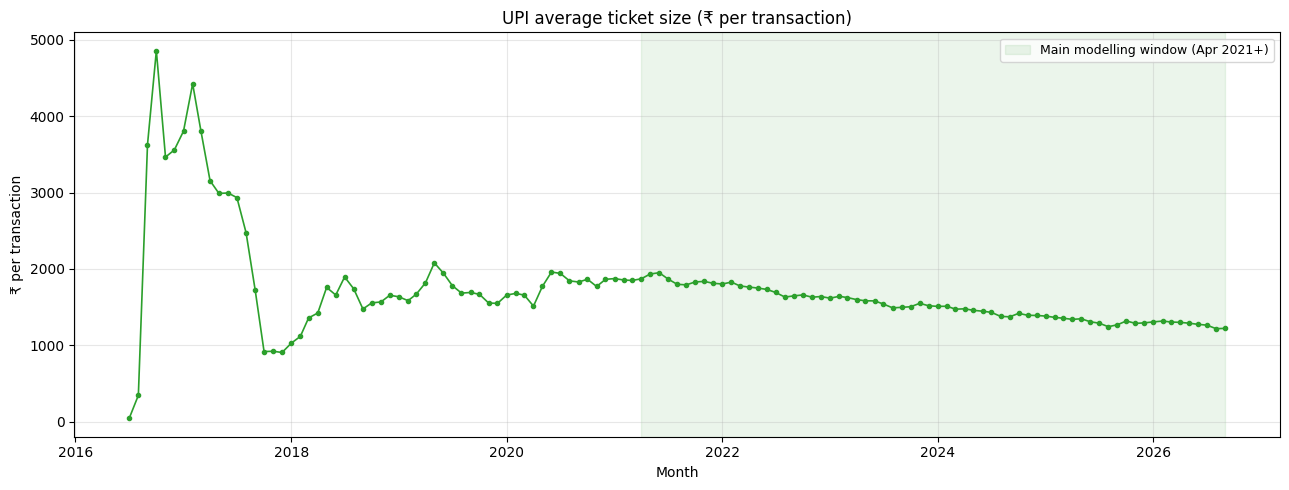

Ticket size in main window: mean 1522, min 1217, max 1950


In [4]:
fig, ax = plt.subplots()
ax.plot(df["month"], df["avg_ticket_size_inr"], marker="o", ms=3, lw=1.2, color="#2ca02c")
ax.axvspan(MODEL_START, df["month"].max(), color="green", alpha=0.08,
           label="Main modelling window (Apr 2021+)")
ax.set_title("UPI average ticket size (₹ per transaction)")
ax.set_ylabel("₹ per transaction")
ax.set_xlabel("Month")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGDIR / "02_ticket_size.png", dpi=120)
plt.show()

win = df[df["month"] >= MODEL_START]["avg_ticket_size_inr"]
print("Ticket size in main window: mean %.0f, min %.0f, max %.0f" % (win.mean(), win.min(), win.max()))

## Plot 3 — Year-on-year volume growth (%)

We start this plot at **2018**: in 2017 the growth rates were astronomically
large (up to ~76,860%) because they were measured off the near-zero 2016 base.
Those are real but not informative, so they are excluded for readability.

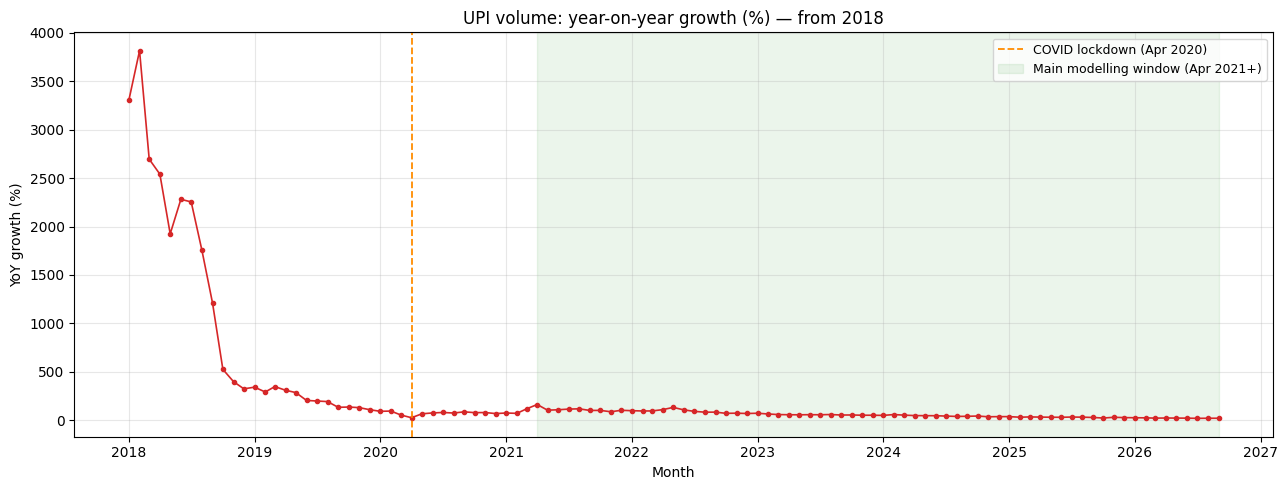

In [5]:
yoy = df[df["month"] >= "2018-01-01"].copy()

fig, ax = plt.subplots()
ax.plot(yoy["month"], yoy["yoy_volume_pct"], marker="o", ms=3, lw=1.2, color="#d62728")
ax.axvline(COVID, color="darkorange", ls="--", lw=1.3, label="COVID lockdown (Apr 2020)")
ax.axvspan(MODEL_START, df["month"].max(), color="green", alpha=0.08,
           label="Main modelling window (Apr 2021+)")

ax.set_title("UPI volume: year-on-year growth (%) — from 2018")
ax.set_ylabel("YoY growth (%)")
ax.set_xlabel("Month")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGDIR / "03_yoy_volume_growth.png", dpi=120)
plt.show()

## Structural breaks — what we see, in plain language

A **structural break** is a point where the data starts behaving differently —
a change in level (a jump/drop) or in *speed* (the trend itself changes).

1. **Demonetisation (Nov 2016) — the launch accelerant.**
   UPI was brand new and tiny: Oct 2016 = 0.10 Mn transactions. Right at
   demonetisation it jumped to **0.29 Mn (Nov)** and **1.99 Mn (Dec)** — a
   ×20 move in two months, and the number of banks live on UPI rose from 26 to
   35. So here demonetisation **coincides with UPI's first real take-off**, not a
   fall. (Worded as *coincides with* — we cannot prove causation from one event.)

2. **COVID lockdown (Apr 2020) — the clearest negative break.**
   Volume fell from **1,246.84 Mn (Mar 2020) to 999.57 Mn (Apr 2020)**, i.e.
   **−19.8% month-on-month**, and average daily volume fell from 40.2 to
   **33.3 Mn/day**. It recovered quickly (May 2020 back to 1,234.50 Mn).
   Structurally, COVID **slowed the growth rate**: YoY growth slowed from about
   +96% (Feb 2020) to about +28% (Apr 2020) before climbing again. So the *level* dipped, but
   the bigger effect was on *momentum*.

3. **Slowing momentum after 2021 (not a single date).**
   As the base became large, YoY growth decelerated from **+164% (Apr 2021,
   against a COVID-depressed base)** down to a stable **low-20s%** by mid-2026
   (Jul 2026 = +21.5%). This is normal maturation, not a break, but it matters
   for forecasting: growth is no longer explosive.

In [6]:
# Show the two break windows as tables so the numbers above are reproducible.
cols = ["month", "volume_mn", "avg_daily_volume", "mom_volume_pct", "yoy_volume_pct", "banks_live"]

print("DEMONETISATION window (Aug 2016 – Feb 2017)")
print(df.loc[(df.month >= "2016-08-01") & (df.month <= "2017-02-01"), cols].to_string(index=False))

print("\nCOVID window (Jan 2020 – Sep 2020)")
print(df.loc[(df.month >= "2020-01-01") & (df.month <= "2020-09-01"), cols].to_string(index=False))

DEMONETISATION window (Aug 2016 – Feb 2017)
     month  volume_mn  avg_daily_volume  mom_volume_pct  yoy_volume_pct  banks_live
2016-08-01       0.09          0.002903        0.000000             NaN        21.0
2016-09-01       0.09          0.003000        0.000000             NaN        25.0
2016-10-01       0.10          0.003226       11.111111             NaN        26.0
2016-11-01       0.29          0.009667      190.000000             NaN        30.0
2016-12-01       1.99          0.064194      586.206897             NaN        35.0
2017-01-01       4.46          0.143871      124.120603             NaN        36.0
2017-02-01       4.38          0.156429       -1.793722             NaN        44.0

COVID window (Jan 2020 – Sep 2020)
     month  volume_mn  avg_daily_volume  mom_volume_pct  yoy_volume_pct  banks_live
2020-01-01    1305.02         42.097419       -0.258331       93.982906       144.0
2020-02-01    1325.69         45.713448        1.583884       96.634480       14

## Odd months — the calendar-length trap (and a couple worth noting)

Because raw monthly totals depend on how many days the month has, the *month-on-month*
percentage will dive whenever a 30-day month follows a 31-day month — even if
nothing real changed. That is why we model **average daily** volume.

In [7]:
win = df[df["month"] >= MODEL_START].dropna(subset=["mom_volume_pct"]).copy()
neg = win[win["mom_volume_pct"] < 0]

print("Negative-MoM months in the main window:", len(neg), "of", len(win))
print("\nOf those negative months, how many are 28/30/31 days?")
print(neg["days_in_month"].value_counts().sort_index().to_string())
print("\n=> 30-day months dominate the declines: the drop is often just a shorter month.")

print("\nLargest genuine single-month drops (full history):")
print(df.dropna(subset=["mom_volume_pct"]).nsmallest(8, "mom_volume_pct")[
    ["month", "volume_mn", "mom_volume_pct"]].to_string(index=False))

Negative-MoM months in the main window: 22 of 66

Of those negative months, how many are 28/30/31 days?
days_in_month
28     4
29     1
30    16
31     1

=> 30-day months dominate the declines: the drop is often just a shorter month.

Largest genuine single-month drops (full history):
     month  volume_mn  mom_volume_pct
2020-04-01     999.57      -19.831735
2024-11-01   15482.02       -6.650298
2023-02-01    7534.76       -6.247815
2019-05-01     733.54       -6.171734
2026-02-01   20394.18       -6.032500
2020-03-01    1246.84       -5.947846
2025-02-01   16106.19       -5.235408
2021-05-01    2539.57       -3.842775


**Reading the odd months:**

- **Apr 2020 (−19.8%)** is the only *large* drop that is clearly real — COVID.
- **2023-02 (−6.2%), 2025-02 (−5.2%), 2026-02 (−6.0%)**: February has only 28
  days, so its *total* is smaller than January's 31 days. On a per-day basis this
  mostly disappears — a pure calendar artefact.
- **2024-11** is a real dip: **−3.5%** once we compare *average daily* volume
  (the raw monthly total was −6.7%, inflated by November having 30 days to
  October's 31). Diwali fell on **31 Oct – 1 Nov 2024**, so festive shopping may
  have landed mostly in *October*. We only say this is **associated with**
  festival timing; we do not claim it as the proven cause.
- Many other small negatives (e.g. 2022-04, 2024-04) are 30-day-month effects.

**Takeaways to carry into modelling**

1. Growth is **multiplicative** (each year ≈ ×1.2), so modelling **log**
   average-daily-volume is appropriate.
2. The **base blew up after 2021**; include the sensitivity window (2019+) later
   to check robustness.
3. **Undocumented calendar effects exist** (month length, festival timing) →
   good candidates for a festival/seasonal component.
4. 2016 is unusable for modelling (near-zero, unstable ticket size).